## Preparation

In [ ]:
!nvidia-smi #check if GPU is available | cuda version | driver NVIDIA

In [ ]:
#install dependencies
!pip install numpy matplotlib scikit-learn seaborn tqdm
!pip install torch --index-url https://download.pytorch.org/whl/cu132

In [ ]:
!python.exe -m pip install --upgrade pip

## Main part

In [1]:
from __future__ import annotations

from IPython.display import display, HTML
display(HTML('<style>.container { width:100% !important; }</style>'))

In [2]:
from pathlib import Path

import numpy as np

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.datasets import fetch_openml

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('dark')
sns.set_theme(rc={'figure.figsize': (10, 10), 'axes.grid': False})

from tqdm.auto import tqdm


c:\Users\eds\Documents\NN\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
rng = np.random.default_rng(seed=42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
def plot_grid(X, ncols=2, nrows=2, figsize=(10, 10), hide_axes=True):
    fig, ax = plt.subplots(ncols=ncols, nrows=nrows, figsize=figsize)
    imgs = X[rng.choice(np.arange(X.shape[0]), size=ax.shape)].reshape(*ax.shape, 28, 28)
    for i in range(ax.shape[0]):
        for j in range(ax.shape[1]):
            ax[i, j].imshow(imgs[i, j], cmap='gray')
            if hide_axes:
                ax[i, j].get_xaxis().set_visible(False)
                ax[i, j].get_yaxis().set_visible(False)

def plot_grid_and_label(X, y, model, ncols=2, nrows=2, figsize=(10, 10), hide_axes=True, flatten_image=True, label_description=None):
    fig, ax = plt.subplots(ncols=ncols, nrows=nrows, figsize=figsize)
    idx = rng.choice(np.arange(X.shape[0]), size=ax.shape)
    imgs, labels = X[idx], y[idx]
    inputs = imgs.reshape(-1, *imgs.shape[2:])

    if flatten_image:
        inputs = inputs.reshape(nrows * ncols, -1)

    map_label = (lambda x: x) if label_description is None else (lambda x: label_description[x])

    preds = np.argmax(nn.Softmax(dim=-1)(model.predict(inputs)), axis=-1).reshape(nrows, ncols)
    for i in range(ax.shape[0]):
        for j in range(ax.shape[1]):
            ax[i, j].imshow(imgs[i, j], cmap='gray')
            ax[i, j].set_title(f'label: {map_label(labels[i, j])}, prediction: {map_label(preds[i, j])}')
            if hide_axes:
                ax[i, j].get_xaxis().set_visible(False)
                ax[i, j].get_yaxis().set_visible(False)

In [5]:
label_description = [
     'A',   'I',   'U',  'E',  'O',
    'KA',  'KI',  'KU', 'KE', 'KO',
    'SA', 'SHI',  'SU', 'SE', 'SO',
    'TA', 'CHI', 'TSU', 'TE', 'TO',
    'NA',  'NI',  'NU', 'NE', 'NO',
    'HA',  'HI',  'FU', 'HE', 'HO',
    'MA',  'MI',  'MU', 'ME', 'MO',
    'YA',         'YU',       'YO',
    'RA',  'RI',  'RU', 'RE', 'RO',
    'WA',  'II',        'EE', 'WO',
     'N',  'IT'
]

In [7]:
X, y = fetch_openml('Kuzushiji-49', version=1, return_X_y=True, as_frame=False, parser='auto')
y = np.array(list(map(int, y)))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

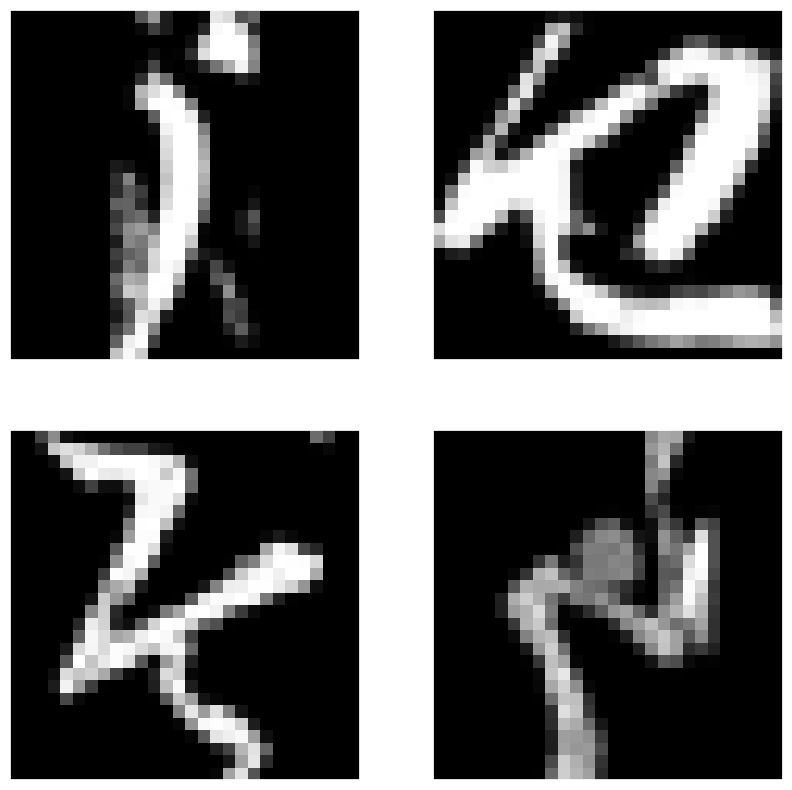

In [8]:
plot_grid(X_train)

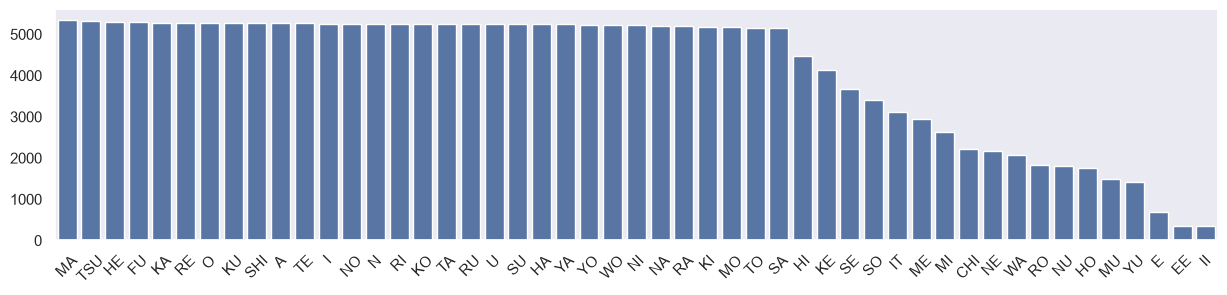

In [9]:
counts = { j: np.sum(y_train == i) for i, j in enumerate(label_description) }
sorted_counts = dict(sorted(counts.items(), key=lambda x: x[1], reverse=True))
plt.figure(figsize=(15, 3))
sns.barplot(x=list(sorted_counts.keys()), y=list(sorted_counts.values()))
plt.xticks(rotation=45)
plt.show()

Наблюдается дисбаланс классов:
- можно при разделять выборку стратисфицируя (соблюдать распределение классов как в выборке)
- Использовать class_weidgths, увеличить штраф модели за ошибки на редких классах
- Работать с данными:
  - Аугментация
  - Уменьшить кол-во частых классов

In [10]:
class KuzushijiDataset(Dataset):
    def __init__(self, X, y, flatten_image=False):
        self.X = torch.as_tensor(X, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.long)
        self.flatten_image = flatten_image

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        x = self.X[index] / 255.0

        if self.flatten_image:
            x = x.reshape(784)
        else:
            x = x.reshape(1, 28, 28)

        return x, self.y[index]


def loader(images, labels, batch_size=32, shuffle=True, flatten_image=False):
    dataset = KuzushijiDataset(
        images,
        labels,
        flatten_image=flatten_image
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )

In [11]:
def evaluate(model, data_loader, criterion, device=device):
    model.eval()

    loss, n = 0., 0
    y_true, y_pred = [], []

    with torch.no_grad():
        for x, y in data_loader:
            x, y = x.to(device), y.to(device)

            y_hat = model(x)
            batch_loss = criterion(y_hat, y)

            loss += batch_loss.item() * x.size(0)
            n += x.size(0)

            y_true.append(y.cpu().numpy())
            y_pred.append(y_hat.argmax(dim=1).cpu().numpy())

    y_true = np.concatenate(y_true)
    y_pred = np.concatenate(y_pred)

    return {
        'loss': loss / n,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred)
    }

def train(
    model,
    train_loader,
    valid_loader,
    criterion,
    optimizer,
    scheduler,
    count_epochs=10,
    device=device,
    checkpoint="./checkpoints/mlp_kuzushiji.pth"
):
    history = {
        'train_loss': [],
        'train_acc': [],
        'valid_loss': [],
        'valid_acc': [],
        'valid_balanced_acc': []
    }

    checkpoint = Path(checkpoint)
    checkpoint.parent.mkdir(parents=True, exist_ok=True)

    best_score = -1.0

    for epoch in range(count_epochs):
        model.train()

        loss, n = 0., 0
        y_true, y_pred = [], []

        for x, y in tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{count_epochs}"
        ):
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            outputs = model(x)
            batch_loss = criterion(outputs, y)

            batch_loss.backward()
            optimizer.step()

            loss += batch_loss.item() * x.size(0)
            n += x.size(0)

            y_true.append(y.detach().cpu().numpy())
            y_pred.append(outputs.argmax(dim=1).detach().cpu().numpy())

        train_loss = loss / n
        train_acc = accuracy_score(
            np.concatenate(y_true),
            np.concatenate(y_pred)
        )

        valid_metrics = evaluate(
            model,
            valid_loader,
            criterion,
            device
        )

        valid_loss = valid_metrics['loss']
        valid_acc = valid_metrics['accuracy']
        valid_balanced_acc = valid_metrics['balanced_accuracy']

        # ReduceLROnPlateau с mode='max'
        scheduler.step(valid_balanced_acc)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['valid_loss'].append(valid_loss)
        history['valid_acc'].append(valid_acc)
        history['valid_balanced_acc'].append(valid_balanced_acc)

        if valid_balanced_acc > best_score:
            best_score = valid_balanced_acc
            torch.save(model.state_dict(), checkpoint)

        print(
            f"Epoch {epoch + 1:02d}/{count_epochs} | "
            f"train_loss={train_loss:.4f} | "
            f"train_acc={train_acc:.4f} | "
            f"valid_loss={valid_loss:.4f} | "
            f"valid_acc={valid_acc:.4f} | "
            f"valid_bal_acc={valid_balanced_acc:.4f}"
        )

    model.load_state_dict(
        torch.load(checkpoint, map_location=device, weights_only=True)
    )

    return history

In [12]:
class_weights =  torch.tensor(
    compute_class_weight('balanced', classes=np.arange(49), y=y_train),
    dtype=torch.float,
    device=device
)

In [13]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, output_size=49):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(0.2),

            nn.Linear(128, 49)
        )

    def forward(self, x):
        x = x.reshape(x.size(0), -1)
        return self.model(x)

In [14]:
dataset_flatten_train = loader(X_train, y_train, batch_size=32, shuffle=True, flatten_image=True)
dataset_flatten_test = loader(X_test, y_test, batch_size=32, shuffle=False, flatten_image=True)

In [15]:
model_mlp = MLP(input_size=784, hidden_size=128, output_size=49).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(
    model_mlp.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=2
)


In [16]:
history_mlp = train(
    model=model_mlp,
    train_loader=dataset_flatten_train,
    valid_loader=dataset_flatten_test,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    count_epochs=15,
    device=device
)

Epoch 1/15: 100%|██████████| 6350/6350 [00:14<00:00, 445.59it/s]


Epoch 01/15 | train_loss=1.3494 | train_acc=0.6379 | valid_loss=0.7112 | valid_acc=0.7995 | valid_bal_acc=0.8073


Epoch 2/15: 100%|██████████| 6350/6350 [00:13<00:00, 465.48it/s]


Epoch 02/15 | train_loss=0.9962 | train_acc=0.7202 | valid_loss=0.5889 | valid_acc=0.8349 | valid_bal_acc=0.8400


Epoch 3/15: 100%|██████████| 6350/6350 [00:13<00:00, 463.49it/s]


...

Epoch 13/15 | train_loss=0.5927 | train_acc=0.8256 | valid_loss=0.3644 | valid_acc=0.8992 | valid_bal_acc=0.9022


Epoch 14/15: 100%|██████████| 6350/6350 [00:13<00:00, 467.06it/s]


Epoch 14/15 | train_loss=0.5761 | train_acc=0.8305 | valid_loss=0.3648 | valid_acc=0.9016 | valid_bal_acc=0.9038


Epoch 15/15: 100%|██████████| 6350/6350 [00:13<00:00, 465.61it/s]


Epoch 15/15 | train_loss=0.5704 | train_acc=0.8318 | valid_loss=0.4002 | valid_acc=0.8999 | valid_bal_acc=0.9029


In [ ]:
NUM_CLASSES = 49
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, NUM_CLASSES),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

In [18]:
dataset_cnn_train = loader(X_train, y_train, flatten_image=False, shuffle=True)
dataset_cnn_valid = loader(X_test, y_test, flatten_image=False, shuffle=True)

In [19]:
model_cnn = CNN().to(device)

optimizer_cnn = torch.optim.AdamW(
    model_cnn.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler_cnn = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_cnn,
    mode='max',
    factor=0.5,
    patience=2
)

history_cnn = train(
    model=model_cnn,
    train_loader=dataset_cnn_train,
    valid_loader=dataset_cnn_valid,
    criterion=criterion,
    optimizer=optimizer_cnn,
    scheduler=scheduler_cnn,
    count_epochs=15,
    device=device,
    checkpoint="./checkpoints/cnn_kuzushiji.pth"
)

Epoch 1/15: 100%|██████████| 6350/6350 [00:18<00:00, 349.19it/s]


Epoch 01/15 | train_loss=1.0149 | train_acc=0.7265 | valid_loss=0.3062 | valid_acc=0.9126 | valid_bal_acc=0.9166


Epoch 2/15: 100%|██████████| 6350/6350 [00:17<00:00, 358.92it/s]


Epoch 02/15 | train_loss=0.5372 | train_acc=0.8500 | valid_loss=0.2292 | valid_acc=0.9358 | valid_bal_acc=0.9381


Epoch 3/15: 100%|██████████| 6350/6350 [00:17<00:00, 357.05it/s]


...

Epoch 13/15 | train_loss=0.2422 | train_acc=0.9287 | valid_loss=0.1452 | valid_acc=0.9627 | valid_bal_acc=0.9629


Epoch 14/15: 100%|██████████| 6350/6350 [00:17<00:00, 362.27it/s]


Epoch 14/15 | train_loss=0.2358 | train_acc=0.9292 | valid_loss=0.1499 | valid_acc=0.9634 | valid_bal_acc=0.9631


Epoch 15/15: 100%|██████████| 6350/6350 [00:17<00:00, 357.92it/s]


Epoch 15/15 | train_loss=0.2327 | train_acc=0.9311 | valid_loss=0.1475 | valid_acc=0.9631 | valid_bal_acc=0.9627


MLP balanced accuracy: 90.3806%
CNN balanced accuracy: 96.3138%
Разница: +5.93 п.п.


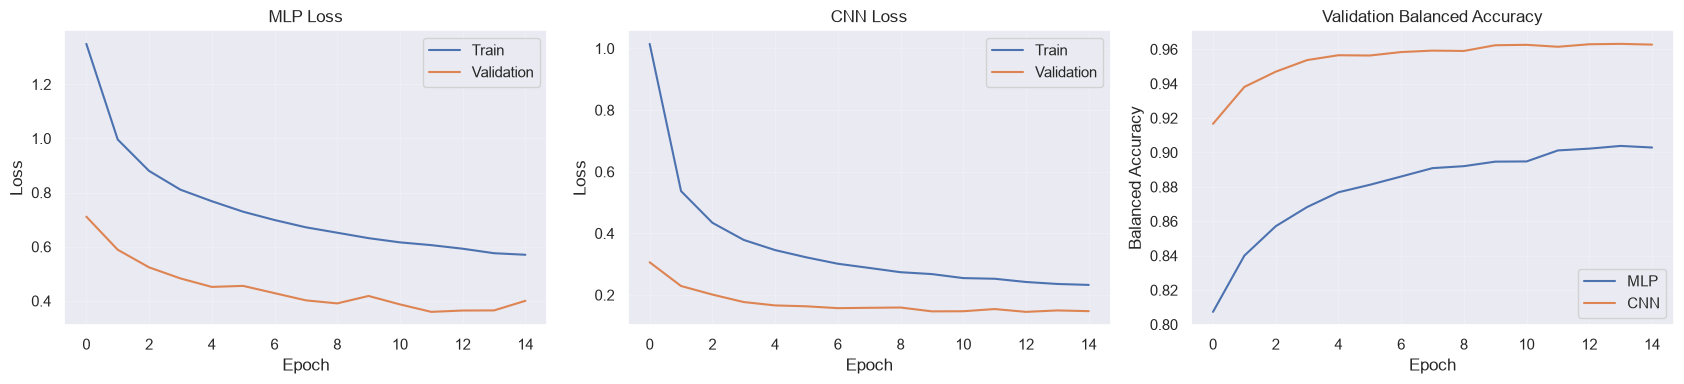

In [21]:
mlp_metrics = evaluate(
    model_mlp, dataset_flatten_test, criterion, device
)

cnn_metrics = evaluate(
    model_cnn, dataset_cnn_valid, criterion, device
)

mlp_score = mlp_metrics['balanced_accuracy']
cnn_score = cnn_metrics['balanced_accuracy']

print(f'MLP balanced accuracy: {mlp_score:.4%}')
print(f'CNN balanced accuracy: {cnn_score:.4%}')
print(f'Разница: {(cnn_score - mlp_score) * 100:+.2f} п.п.')


fig, axs = plt.subplots(1, 3, figsize=(17, 4))

# MLP Loss
axs[0].plot(history_mlp['train_loss'], label='Train')
axs[0].plot(history_mlp['valid_loss'], label='Validation')
axs[0].set_title('MLP Loss')

# CNN Loss
axs[1].plot(history_cnn['train_loss'], label='Train')
axs[1].plot(history_cnn['valid_loss'], label='Validation')
axs[1].set_title('CNN Loss')

# Balanced Accuracy
axs[2].plot(
    history_mlp['valid_balanced_acc'],
    label='MLP'
)
axs[2].plot(
    history_cnn['valid_balanced_acc'],
    label='CNN'
)
axs[2].set_title('Validation Balanced Accuracy')

for ax in axs:
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(alpha=0.2)

axs[0].set_ylabel('Loss')
axs[1].set_ylabel('Loss')
axs[2].set_ylabel('Balanced Accuracy')

plt.tight_layout()
plt.show()

In [33]:
def plot_confusion_matrix(model, data_loader, device, title):
    model.eval()

    y_true, y_pred = [], []

    with torch.no_grad():
        for x, y in data_loader:
            x = x.to(device)

            outputs = model(x)
            predictions = outputs.argmax(dim=1)

            y_true.extend(y.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(49),
        normalize='true'
    )

    fig, ax = plt.subplots(figsize=(10, 10))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=np.arange(49)
    )

    disp.plot(
        ax=ax,
        xticks_rotation=90,
        include_values=False,
        colorbar=True
    )

    ax.set_title(title)

    plt.tight_layout()
    plt.show()

    return cm

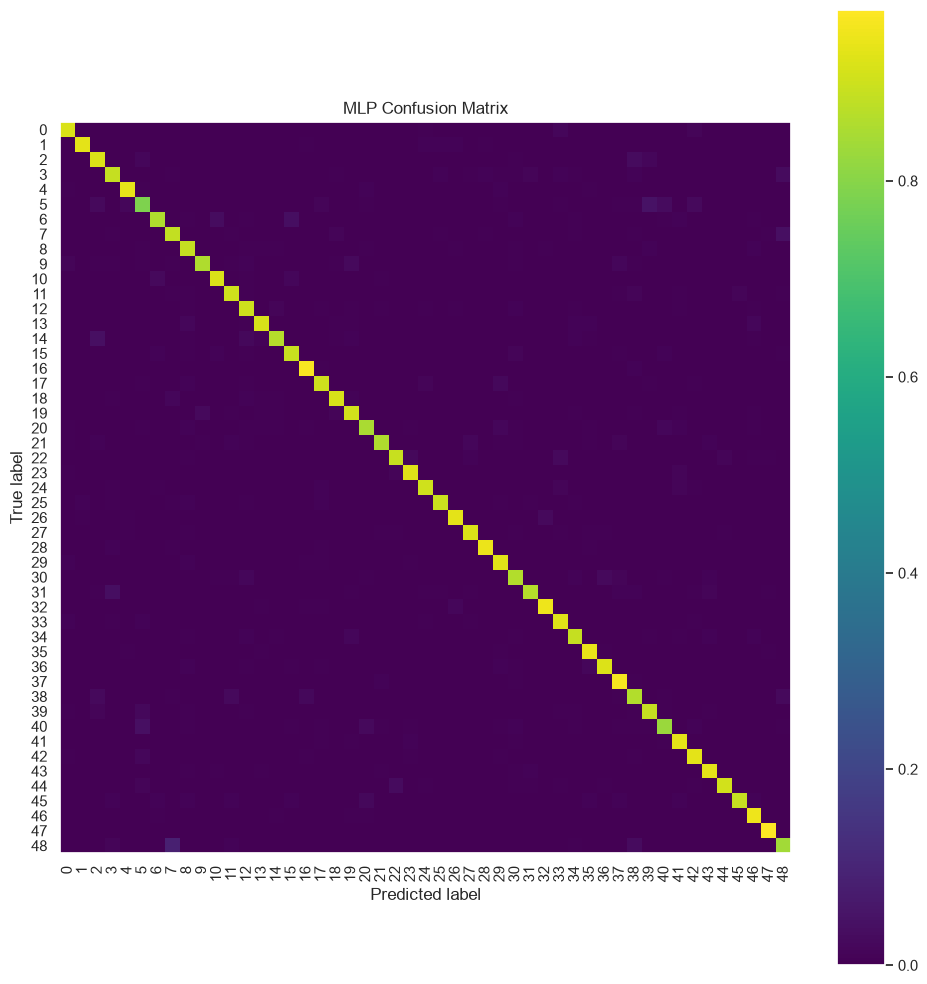

In [34]:
mlp_cm = plot_confusion_matrix(
    model_mlp,
    dataset_flatten_test,
    device,
    title='MLP Confusion Matrix'
)

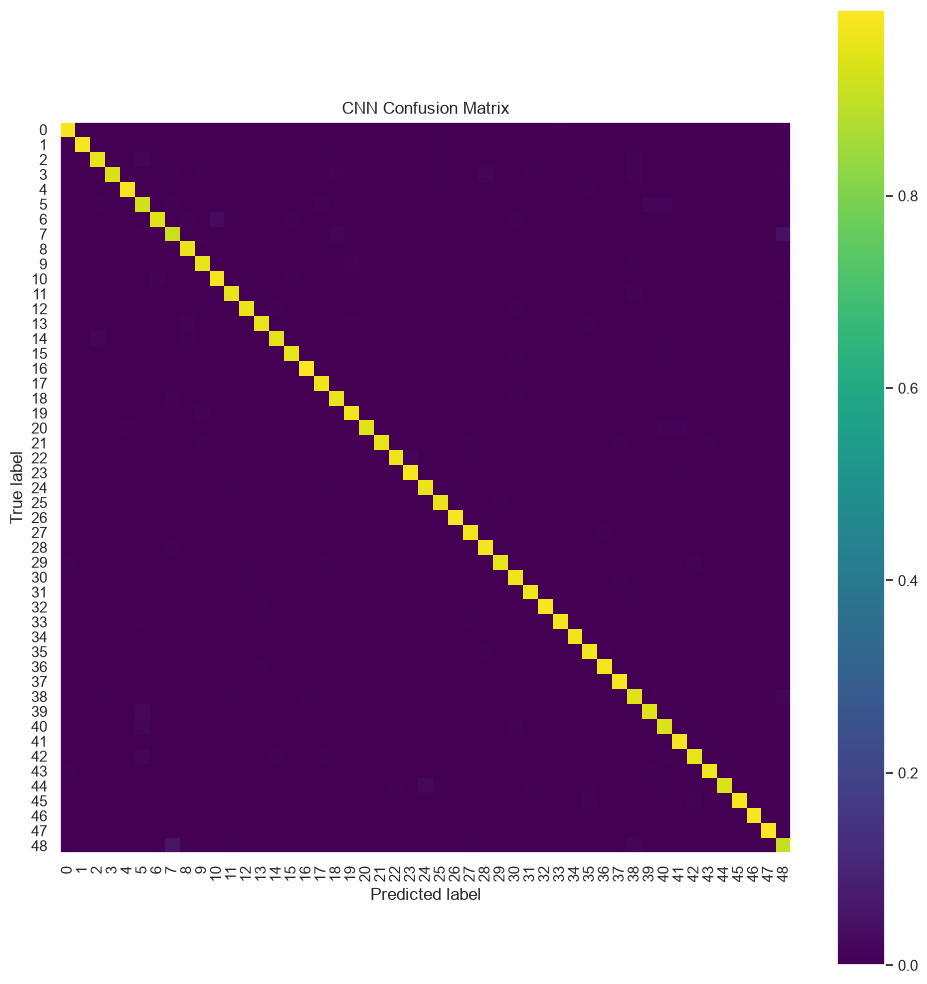

In [35]:
cnn_cm = plot_confusion_matrix(
    model_cnn,
    dataset_cnn_valid,
    device,
    title='CNN Confusion Matrix'
)

In [25]:
def worst_classes_f1(model, data_loader, device, n=5):
    model.eval()

    y_true, y_pred = [], []

    with torch.no_grad():
        for x, y in data_loader:
            x = x.to(device)

            predictions = model(x).argmax(dim=1)

            y_true.extend(y.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(49),
        zero_division=0
    )

    worst = np.argsort(f1)[:n]

    for class_id in worst:
        print(
            f"Class {class_id:2d} | "
            f"Precision: {precision[class_id]:.2%} | "
            f"Recall: {recall[class_id]:.2%} | "
            f"F1: {f1[class_id]:.2%}"
        )

In [27]:
print("MLP:")
worst_classes_f1(model_mlp, dataset_flatten_test, device)

print("\nCNN:")
worst_classes_f1(model_cnn, dataset_cnn_valid, device)

MLP:
Class  3 | Precision: 53.76% | Recall: 89.00% | F1: 67.03%
Class 45 | Precision: 68.99% | Recall: 89.00% | F1: 77.73%
Class 44 | Precision: 71.01% | Recall: 90.91% | F1: 79.73%
Class  5 | Precision: 84.27% | Recall: 78.72% | F1: 81.40%
Class 29 | Precision: 73.96% | Recall: 93.12% | F1: 82.44%

CNN:
Class 48 | Precision: 84.81% | Recall: 90.48% | F1: 87.55%
Class  5 | Precision: 89.65% | Recall: 92.42% | F1: 91.01%
Class 45 | Precision: 87.50% | Recall: 98.00% | F1: 92.45%
Class  7 | Precision: 93.54% | Recall: 91.48% | F1: 92.50%
Class  3 | Precision: 92.42% | Recall: 93.30% | F1: 92.86%
